In [15]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import seaborn as sns

print("Seaborn installed successfully!")
print(sns.__version__)

Seaborn installed successfully!
0.13.2


In [17]:
# Cell 1: Project mein use hone wali sabhi important libraries import kar rahe hain.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

# Scikit-learn: preprocessing aur model pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Scikit-learn: machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Scikit-learn: evaluation metrics aur charts
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Model save/load karne ke liye
import joblib

print('All libraries imported successfully!')

All libraries imported successfully!


In [4]:
# Cell 2: ZIP file se CSV dataset load kar rahe hain.

df = pd.read_csv(
    'car_insurance_claim.csv.zip',
    compression='zip',
    encoding='utf-8-sig'
)

print('Dataset loaded successfully!')
display(df.head())

Dataset loaded successfully!


,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,...,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,...,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,...,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,...,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,...,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,...,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban


In [5]:
# Cell 3: Dataset ka size, columns, data types aur summary check kar rahe hain.

print('Rows and Columns:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())
print('\nInformation:')
df.info()
print('\nFirst 5 rows:')
display(df.head())
print('\nNumerical summary:')
display(df.describe().T)

Rows and Columns: (10302, 27)

Column Names:
['ID', 'KIDSDRIV', 'BIRTH', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME', 'CAR_USE', 'BLUEBOOK', 'TIF', 'CAR_TYPE', 'RED_CAR', 'OLDCLAIM', 'CLM_FREQ', 'REVOKED', 'MVR_PTS', 'CLM_AMT', 'CAR_AGE', 'CLAIM_FLAG', 'URBANICITY']

Information:
<class 'pandas.DataFrame'>
RangeIndex: 10302 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ID          10302 non-null  int64  
 1   KIDSDRIV    10302 non-null  int64  
 2   BIRTH       10302 non-null  str    
 3   AGE         10295 non-null  float64
 4   HOMEKIDS    10302 non-null  int64  
 5   YOJ         9754 non-null   float64
 6   INCOME      9732 non-null   str    
 7   PARENT1     10302 non-null  str    
 8   HOME_VAL    9727 non-null   str    
 9   MSTATUS     10302 non-null  str    
 10  GENDER      10302 non-null  str    
 11  EDUCATION

,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,...,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,...,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,...,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,...,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,...,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,...,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
ID,10302.0,4.956631e+08,2.864675e+08,63175.0,244286856.0,497004293.0,739455069.0,999926368.0
KIDSDRIV,10302.0,1.692875e-01,5.065116e-01,0.0,0.0,0.0,0.0,4.0
AGE,10295.0,4.483740e+01,8.606445e+00,16.0,39.0,45.0,51.0,81.0
HOMEKIDS,10302.0,7.204426e-01,1.116323e+00,0.0,0.0,0.0,1.0,5.0
YOJ,9754.0,1.047406e+01,4.108943e+00,0.0,9.0,11.0,13.0,23.0
TRAVTIME,10302.0,3.341642e+01,1.586969e+01,5.0,22.0,33.0,44.0,142.0
TIF,10302.0,5.329159e+00,4.110795e+00,1.0,1.0,4.0,7.0,25.0
CLM_FREQ,10302.0,8.007183e-01,1.154079e+00,0.0,0.0,0.0,2.0,5.0
MVR_PTS,10302.0,1.710153e+00,2.159015e+00,0.0,0.0,1.0,3.0,13.0
CAR_AGE,9663.0,8.298148e+00,5.714450e+00,-3.0,1.0,8.0,12.0,28.0


In [6]:
# Cell 4: Sirf poori tarah duplicate rows remove kar rahe hain.

print('Exact duplicate rows before:', df.duplicated().sum())
df = df.drop_duplicates().copy()
print('Exact duplicate rows after:', df.duplicated().sum())
print('Updated dataset shape:', df.shape)
print('Repeated ID rows:', df['ID'].duplicated().sum())

Exact duplicate rows before: 1
Exact duplicate rows after: 0
Updated dataset shape: (10301, 27)
Repeated ID rows: 1548


In [7]:
# Cell 5: Target variable ki class count aur percentage check kar rahe hain.

print('Target value counts:')
print(df['CLAIM_FLAG'].value_counts())

print('\nTarget percentage:')
print((df['CLAIM_FLAG'].value_counts(normalize=True) * 100).round(2))

# Target ka simple meaning
print('\n0 = No Claim, 1 = Claim')

Target value counts:
CLAIM_FLAG
0    7555
1    2746
Name: count, dtype: int64

Target percentage:
CLAIM_FLAG
0    73.34
1    26.66
Name: proportion, dtype: float64

0 = No Claim, 1 = Claim


In [9]:
# Cell 6: CLM_AMT aur CLAIM_FLAG ka relation check kar rahe hain.
# CLM_AMT claim ke baad pata chalne wali amount ho sakti hai, isliye ise input mein dena leakage hoga.

claim_amount_check = pd.to_numeric(
    df['CLM_AMT'].astype(str).str.replace(r'[$,]', '', regex=True),
    errors='coerce'
)

leakage_table = pd.crosstab(
    df['CLAIM_FLAG'],
    claim_amount_check > 0,
    rownames=['CLAIM_FLAG'],
    colnames=['CLM_AMT greater than 0']
)

display(leakage_table)
print('Match percentage:', round(((claim_amount_check > 0).astype(int) == df['CLAIM_FLAG']).mean() * 100, 2), '%')
print('Decision: CLM_AMT ko model features se remove karenge.')

CLM_AMT greater than 0,False,True
CLAIM_FLAG,,
0,7555,0
1,0,2746


Match percentage: 100.0 %
Decision: CLM_AMT ko model features se remove karenge.


In [10]:
# Cell 7: Dollar sign aur comma hata kar currency columns ko numbers mein convert kar rahe hain.

money_columns = ['INCOME', 'HOME_VAL', 'BLUEBOOK', 'OLDCLAIM']

for col in money_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(r'[$,]', '', regex=True),
        errors='coerce'
    )

print('Currency columns converted successfully!')
display(df[money_columns].head())
print(df[money_columns].dtypes)

Currency columns converted successfully!


,INCOME,HOME_VAL,BLUEBOOK,OLDCLAIM
0,67349.0,0.0,14230,4461
1,91449.0,257252.0,14940,0
2,52881.0,0.0,21970,0
3,16039.0,124191.0,4010,38690
4,NaN,306251.0,15440,0


INCOME      float64
HOME_VAL    float64
BLUEBOOK      int64
OLDCLAIM      int64
dtype: object


In [11]:
# Cell 8: Har column mein missing values count aur percentage check kar rahe hain.

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by='Missing Count', ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
OCCUPATION,665,6.46
CAR_AGE,639,6.20
HOME_VAL,575,5.58
INCOME,570,5.53
YOJ,548,5.32
AGE,7,0.07
BIRTH,0,0.00
HOMEKIDS,0,0.00
PARENT1,0,0.00
ID,0,0.00


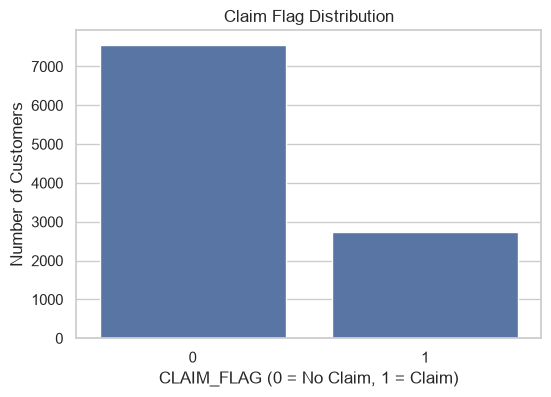

In [18]:
# Cell 9: Claim aur No Claim records ka count graph bana rahe hain.

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='CLAIM_FLAG')
plt.title('Claim Flag Distribution')
plt.xlabel('CLAIM_FLAG (0 = No Claim, 1 = Claim)')
plt.ylabel('Number of Customers')
plt.show()

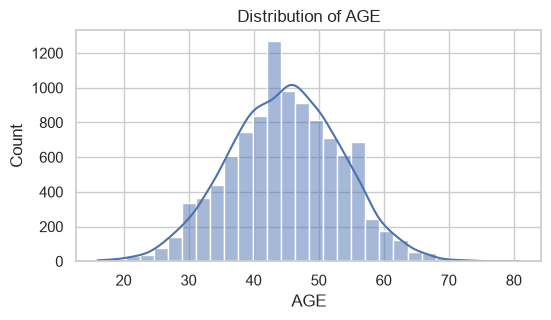

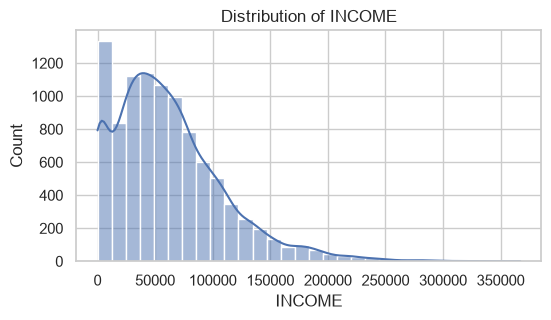

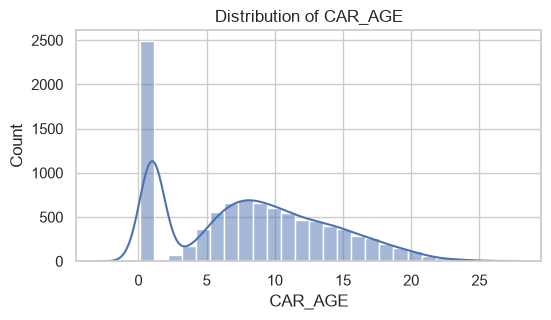

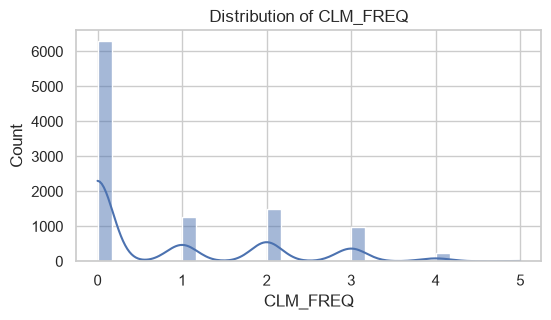

In [19]:
# Cell 10: Kuch important numerical features ke histograms dekh rahe hain.

columns_to_plot = ['AGE', 'INCOME', 'CAR_AGE', 'CLM_FREQ']

for col in columns_to_plot:
    plt.figure(figsize=(6, 3))
    sns.histplot(data=df, x=col, bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

,CAR_USE,Claim Rate
0,Commercial,0.345738
1,Private,0.220516


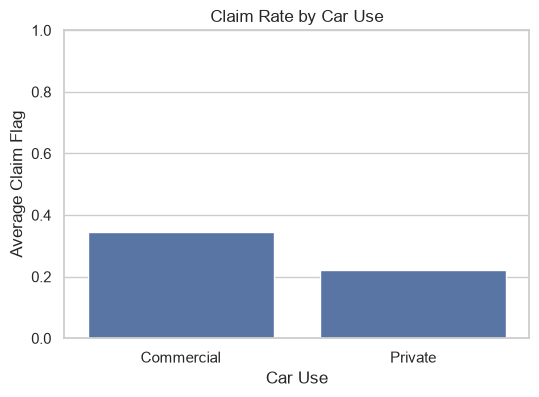

In [20]:
# Cell 11: Private aur Commercial car use ka claim rate compare kar rahe hain.

claim_rate_by_use = (
    df.groupby('CAR_USE')['CLAIM_FLAG']
      .mean()
      .sort_values(ascending=False)
      .reset_index(name='Claim Rate')
)

display(claim_rate_by_use)

plt.figure(figsize=(6, 4))
sns.barplot(data=claim_rate_by_use, x='CAR_USE', y='Claim Rate')
plt.title('Claim Rate by Car Use')
plt.ylabel('Average Claim Flag')
plt.xlabel('Car Use')
plt.ylim(0, 1)
plt.show()

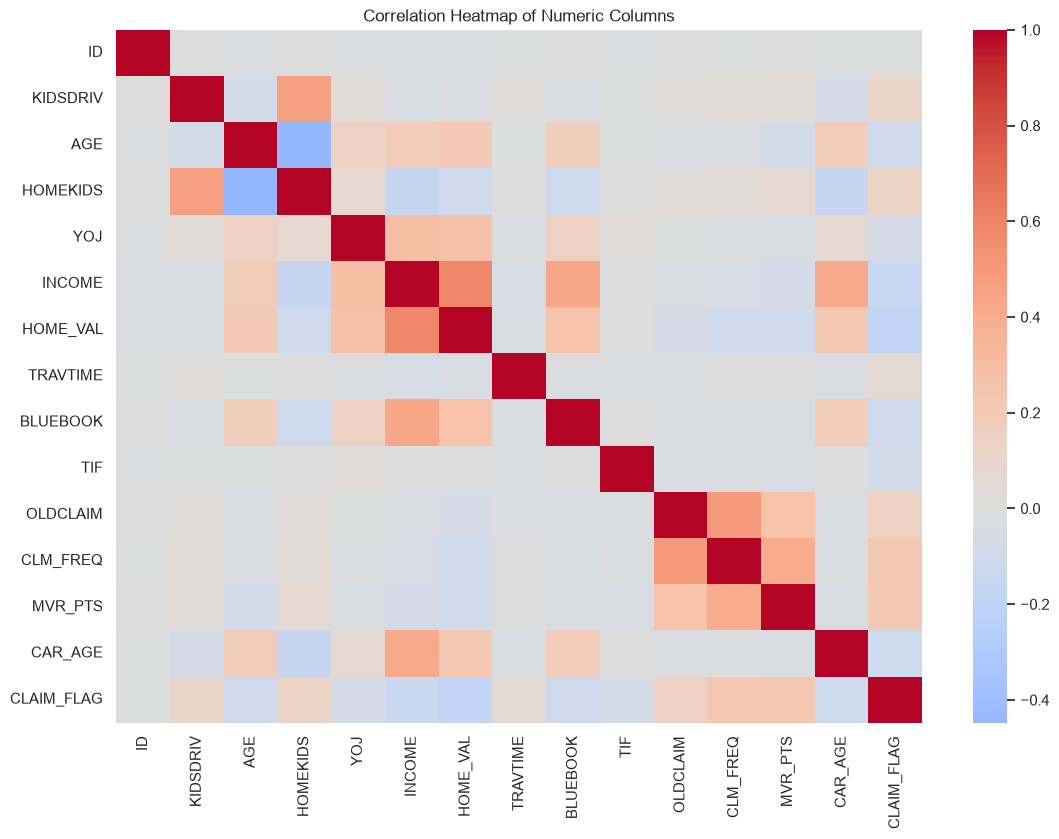

In [21]:
# Cell 12: Numerical columns ka correlation heatmap bana rahe hain.

numeric_data = df.select_dtypes(include=np.number)
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(13, 9))
sns.heatmap(correlation_matrix, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numeric Columns')
plt.show()

In [22]:
# Cell 13: Input features (X), target (y) aur ID groups alag kar rahe hain.

# ID ko model feature nahi banayenge; sirf split mein group ke roop mein use karenge.
groups = df['ID'].copy()

# Target variable
y = df['CLAIM_FLAG'].astype(int)

# Leakage / identifier / duplicate birth information remove karke features banayein
columns_to_drop = ['ID', 'BIRTH', 'CLM_AMT', 'CLAIM_FLAG']
X = df.drop(columns=columns_to_drop)

print('Features shape:', X.shape)
print('Target shape:', y.shape)
print('Group count:', groups.nunique())
print('Feature columns:')
print(X.columns.tolist())

Features shape: (10301, 23)
Target shape: (10301,)
Group count: 8753
Feature columns:
['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME', 'CAR_USE', 'BLUEBOOK', 'TIF', 'CAR_TYPE', 'RED_CAR', 'OLDCLAIM', 'CLM_FREQ', 'REVOKED', 'MVR_PTS', 'CAR_AGE', 'URBANICITY']


In [23]:
# Cell 14: Data ko training aur testing sets mein split kar rahe hain.
# Stratification class ratio maintain karne mein madad karti hai.
# Grouping ek hi ID ko train aur test dono mein aane se rokti hai.

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()
y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()
groups_train = groups.iloc[train_indices]
groups_test = groups.iloc[test_indices]

print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)
print('\nTraining target ratio:')
print(y_train.value_counts(normalize=True).round(3))
print('\nTesting target ratio:')
print(y_test.value_counts(normalize=True).round(3))
print('\nID overlap between train and test:', len(set(groups_train) & set(groups_test)))

Training data: (8240, 23)
Testing data: (2061, 23)

Training target ratio:
CLAIM_FLAG
0    0.733
1    0.267
Name: proportion, dtype: float64

Testing target ratio:
CLAIM_FLAG
0    0.734
1    0.266
Name: proportion, dtype: float64

ID overlap between train and test: 0


In [24]:
# Cell 15: Numeric aur categorical columns ke liye preprocessing pipeline bana rahe hain.

# Numeric aur categorical feature names identify kar rahe hain.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

def make_preprocessor():
    # Numeric: missing value ko median se fill, phir scaling
    numeric_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Categorical: missing value ko most frequent category se fill, phir one-hot encoding
    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Dono pipelines ko ek saath combine kar rahe hain.
    preprocessor = ColumnTransformer(transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ])

    return preprocessor

print('Preprocessing function created!')

Numeric features: ['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'HOME_VAL', 'TRAVTIME', 'BLUEBOOK', 'TIF', 'OLDCLAIM', 'CLM_FREQ', 'MVR_PTS', 'CAR_AGE']
Categorical features: ['PARENT1', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'CAR_USE', 'CAR_TYPE', 'RED_CAR', 'REVOKED', 'URBANICITY']
Preprocessing function created!


In [25]:
# Cell 16: Logistic Regression, Decision Tree aur Random Forest pipelines bana rahe hain.

models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', make_preprocessor()),
        ('model', LogisticRegression(max_iter=2000))
    ]),

    'Decision Tree': Pipeline(steps=[
        ('preprocessor', make_preprocessor()),
        ('model', DecisionTreeClassifier(
            random_state=42,
            max_depth=8,
            min_samples_split=20,
            min_samples_leaf=10
        ))
    ]),

    'Random Forest': Pipeline(steps=[
        ('preprocessor', make_preprocessor()),
        ('model', RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print('Models created:')
print(list(models.keys()))

Models created:
['Logistic Regression', 'Decision Tree', 'Random Forest']


In [26]:
# Cell 17: Teenon models train karke test data par evaluate kar rahe hain.

trained_models = {}
results = []

for model_name, model in models.items():
    print(f'Training: {model_name}')

    # Model ko training data par train karna
    model.fit(X_train, y_train)

    # Test data par class prediction aur Claim probability
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]

    # Evaluation metrics store karna
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_probability)
    })

    trained_models[model_name] = model

print('\nAll models trained successfully!')

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest

All models trained successfully!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7948,0.6810,0.4317,0.5284,0.8169
1,Random Forest,0.7885,0.7055,0.3534,0.4709,0.8159
2,Decision Tree,0.7647,0.5773,0.4353,0.4964,0.7617


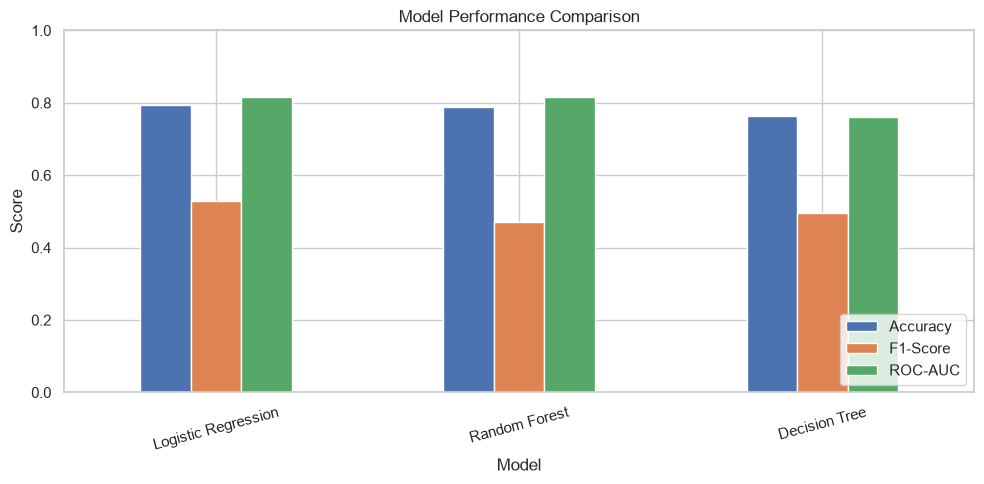

In [27]:
# Cell 18: Sabhi models ke evaluation scores compare kar rahe hain.

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

display(results_df.round(4))

# Models ki Accuracy, F1-score aur ROC-AUC compare karne ka graph
plot_data = results_df.set_index('Model')[['Accuracy', 'F1-Score', 'ROC-AUC']]
plot_data.plot(kind='bar', figsize=(10, 5))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [28]:
# Cell 19: Har trained model ki detailed classification report print kar rahe hain.

for model_name, model in trained_models.items():
    print('\n' + '=' * 60)
    print(model_name)
    print('=' * 60)

    y_pred = model.predict(X_test)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['No Claim', 'Claim'],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    No Claim       0.82      0.93      0.87      1512
       Claim       0.68      0.43      0.53       549

    accuracy                           0.79      2061
   macro avg       0.75      0.68      0.70      2061
weighted avg       0.78      0.79      0.78      2061


Decision Tree
              precision    recall  f1-score   support

    No Claim       0.81      0.88      0.85      1512
       Claim       0.58      0.44      0.50       549

    accuracy                           0.76      2061
   macro avg       0.69      0.66      0.67      2061
weighted avg       0.75      0.76      0.75      2061


Random Forest
              precision    recall  f1-score   support

    No Claim       0.80      0.95      0.87      1512
       Claim       0.71      0.35      0.47       549

    accuracy                           0.79      2061
   macro avg       0.75      0.65      0.67      2061
weighted avg       0.78

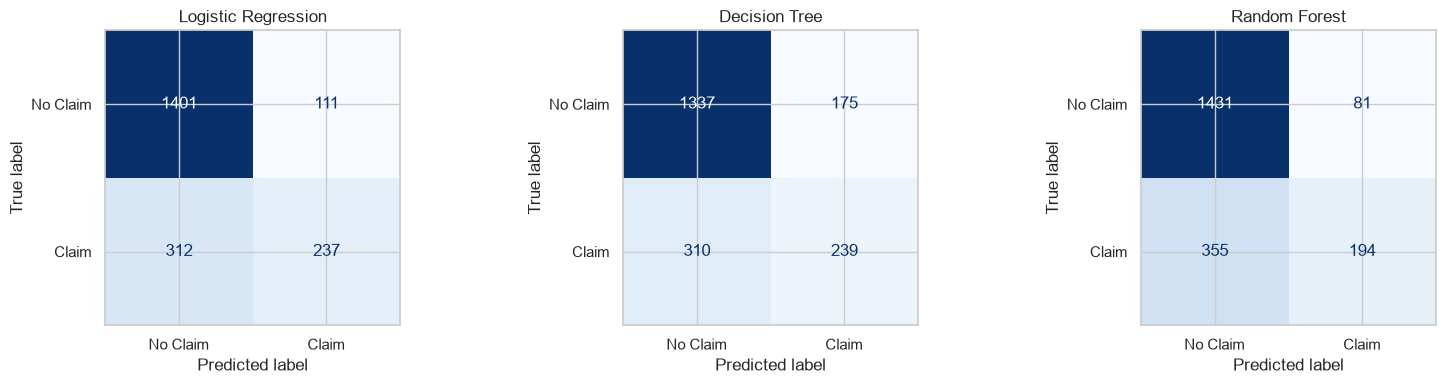

In [29]:
# Cell 20: Teeno models ki confusion matrices ek saath plot kar rahe hain.

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (model_name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=['No Claim', 'Claim'],
        cmap='Blues',
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

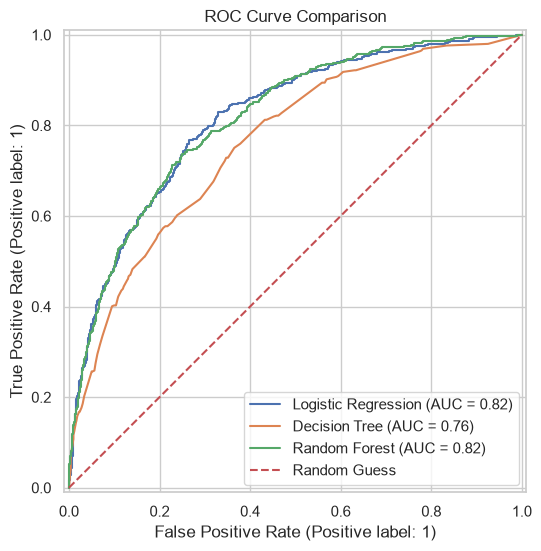

In [30]:
# Cell 21: Teeno models ki ROC curves compare kar rahe hain.

fig, ax = plt.subplots(figsize=(7, 6))

for model_name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

# Random guessing ki reference line
ax.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')
ax.set_title('ROC Curve Comparison')
ax.legend()
plt.show()

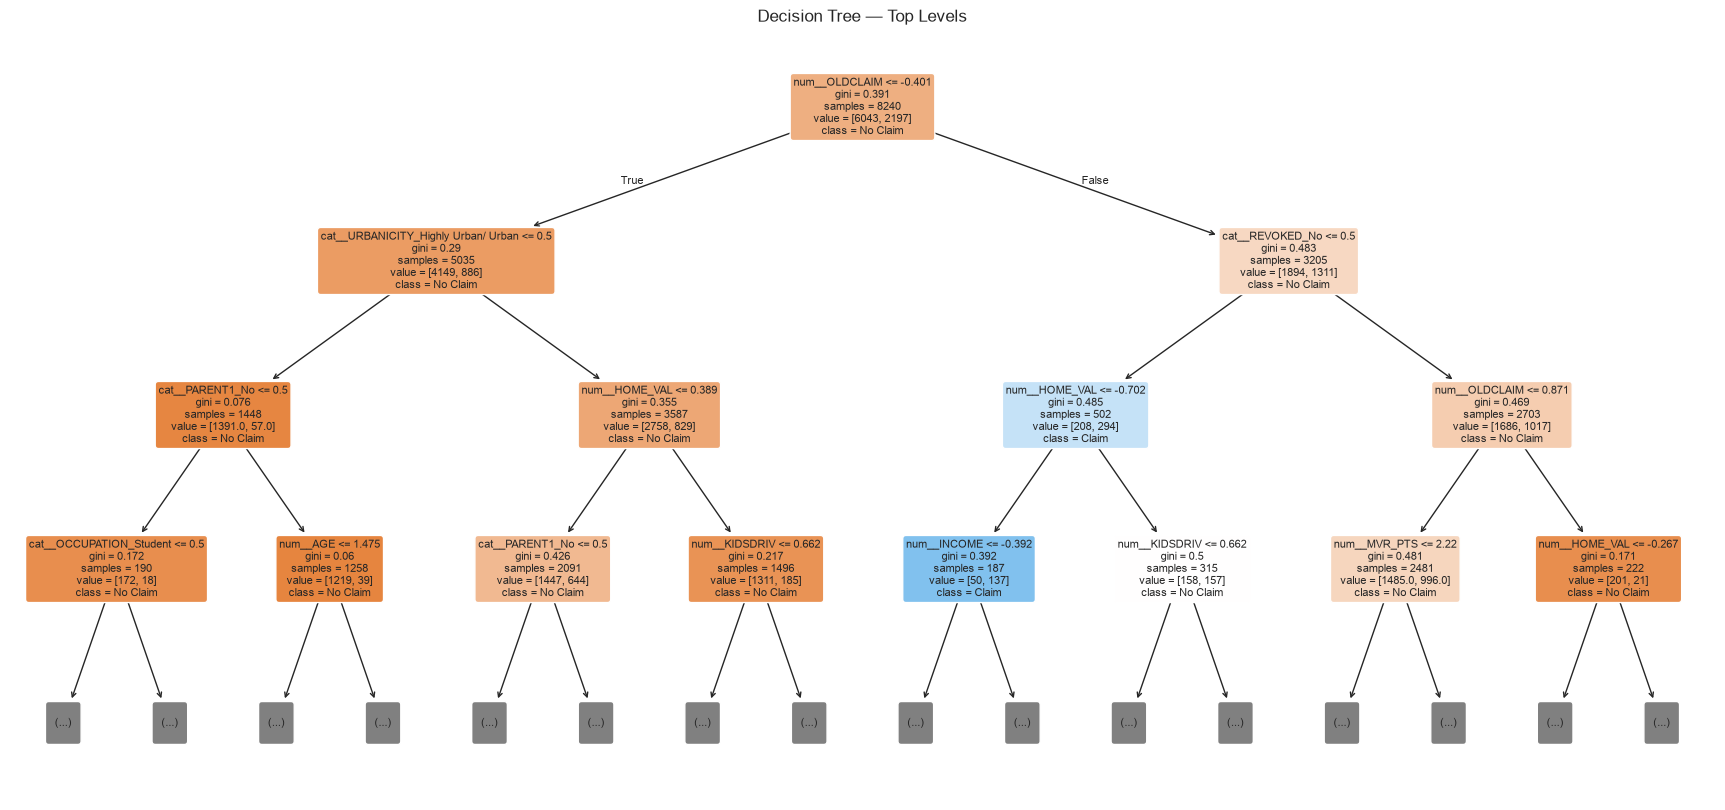

In [31]:
# Cell 22: Trained Decision Tree ke top 3 levels ka visual bana rahe hain.

dt_pipeline = trained_models['Decision Tree']
dt_preprocessor = dt_pipeline.named_steps['preprocessor']
dt_model = dt_pipeline.named_steps['model']

transformed_feature_names = dt_preprocessor.get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(
    dt_model,
    feature_names=transformed_feature_names,
    class_names=['No Claim', 'Claim'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title('Decision Tree — Top Levels')
plt.show()

,Feature,Importance
9,num__OLDCLAIM,0.079397
4,num__INCOME,0.069413
5,num__HOME_VAL,0.065453
7,num__BLUEBOOK,0.064696
10,num__CLM_FREQ,0.057994
6,num__TRAVTIME,0.057742
11,num__MVR_PTS,0.055434
1,num__AGE,0.051000
44,cat__URBANICITY_Highly Urban/ Urban,0.050897
45,cat__URBANICITY_z_Highly Rural/ Rural,0.048986


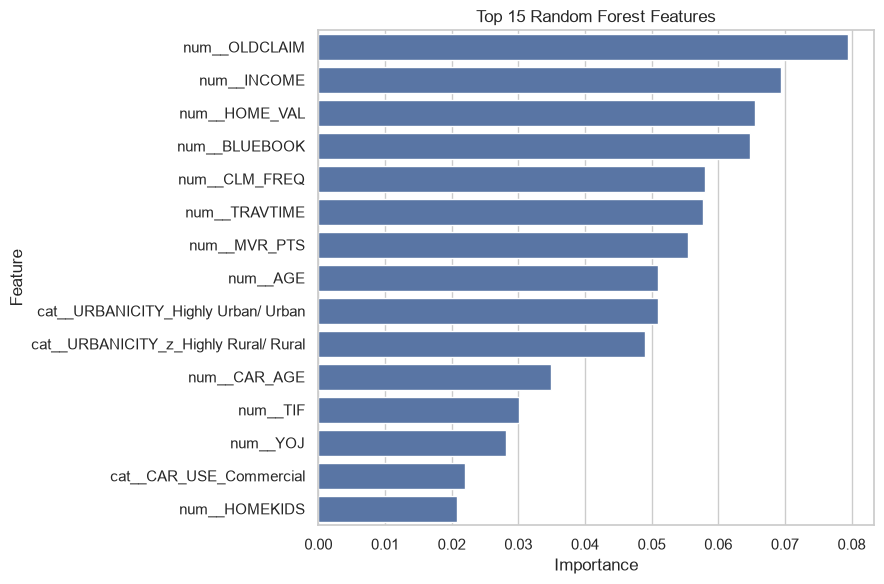

In [32]:
# Cell 23: Random Forest ki top 15 feature importances visualise kar rahe hain.

rf_pipeline = trained_models['Random Forest']
rf_preprocessor = rf_pipeline.named_steps['preprocessor']
rf_model = rf_pipeline.named_steps['model']

rf_feature_names = rf_preprocessor.get_feature_names_out()
rf_importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': rf_feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

top_features = importance_df.head(15)
display(top_features)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x='Importance', y='Feature')
plt.title('Top 15 Random Forest Features')
plt.tight_layout()
plt.show()

In [33]:
# Cell 24: ROC-AUC ke basis par top model select karke ek test sample predict kar rahe hain.

best_model_name = results_df.loc[0, 'Model']
best_model = trained_models[best_model_name]

print('Selected model (highest ROC-AUC):', best_model_name)

# Test set ka ek customer sample le rahe hain
sample_customer = X_test.iloc[[0]]

prediction = int(best_model.predict(sample_customer)[0])
claim_probability = float(best_model.predict_proba(sample_customer)[0, 1])

print('Predicted class:', prediction)
print('Prediction meaning:', 'Claim' if prediction == 1 else 'No Claim')
print('Estimated Claim probability:', round(claim_probability * 100, 2), '%')

print('\nSample customer input:')
display(sample_customer)

Selected model (highest ROC-AUC): Logistic Regression
Predicted class: 0
Prediction meaning: No Claim
Estimated Claim probability: 26.47 %

Sample customer input:


,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,...,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CAR_AGE,URBANICITY
1,0,43.0,0,11.0,91449.0,No,257252.0,z_No,M,z_High School,...,14940,1,Minivan,yes,0,0,No,0,1.0,Highly Urban/ Urban


In [34]:
# Cell 25: Best model pipeline aur model details ko file mein save kar rahe hain.

model_package = {
    'model': best_model,
    'model_name': best_model_name,
    'feature_columns': X.columns.tolist()
}

joblib.dump(model_package, 'car_insurance_claim_best_model.pkl')
print('Model saved as car_insurance_claim_best_model.pkl')

Model saved as car_insurance_claim_best_model.pkl


In [35]:
# Cell 26: Saved model ko load karke prediction dobara check kar rahe hain.

loaded_package = joblib.load('car_insurance_claim_best_model.pkl')
loaded_model = loaded_package['model']

loaded_prediction = int(loaded_model.predict(sample_customer)[0])
loaded_probability = float(loaded_model.predict_proba(sample_customer)[0, 1])

print('Loaded model:', loaded_package['model_name'])
print('Prediction:', 'Claim' if loaded_prediction == 1 else 'No Claim')
print('Claim probability:', round(loaded_probability * 100, 2), '%')

Loaded model: Logistic Regression
Prediction: No Claim
Claim probability: 26.47 %
